In [1]:
!nvidia-smi
!pip install ultralytics -q

Tue Oct 27 05:04:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
import zipfile

# Download from Kaggle official API (this link is reliable)
!curl -L -o /kaggle/working/NEU-DET.zip https://www.kaggle.com/api/v1/datasets/download/kaustubhdikshit/neu-surface-defect-database

# Verify that the downloaded file is a valid zip
try:
    with zipfile.ZipFile("/kaggle/working/NEU-DET.zip", 'r') as zip_ref:
        zip_ref.extractall("/kaggle/working/")
    print("Dataset extraction successful!")
except zipfile.BadZipFile:
    print("Error: The downloaded file is still not a valid zip. Please check if the Kaggle API link is accessible, or manually upload the dataset.")

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 26.4M  100 26.4M    0     0  55.4M      0 --:--:-- --:--:-- --:--:--  169M
Dataset extraction successful!


In [3]:
import glob
import xml.etree.ElementTree as ET
import shutil
from sklearn.model_selection import train_test_split

# Adjust paths based on actual extraction location
img_dir = "/kaggle/working/NEU-DET/train/images"
ann_dir = "/kaggle/working/NEU-DET/train/annotations"

classes = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

# Create YOLO format directory
for split in ["train", "val"]:
    os.makedirs(f"/kaggle/working/datasets/neu-det-yolo/images/{split}", exist_ok=True)
    os.makedirs(f"/kaggle/working/datasets/neu-det-yolo/labels/{split}", exist_ok=True)

def convert_xml(xml_path, img_w=200, img_h=200):
    tree = ET.parse(xml_path)
    lines = []
    for obj in tree.getroot().findall('object'):
        cls_name = obj.find('name').text.strip()
        if cls_name not in classes:
            continue
        cls_id = classes.index(cls_name)
        b = obj.find('bndbox')
        xmin, ymin = float(b.find('xmin').text), float(b.find('ymin').text)
        xmax, ymax = float(b.find('xmax').text), float(b.find('ymax').text)
        xc = ((xmin + xmax) / 2) / img_w
        yc = ((ymin + ymax) / 2) / img_h
        w = (xmax - xmin) / img_w
        h = (ymax - ymin) / img_h
        lines.append(f"{cls_id} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")
    return lines

# Recursively find all jpg files (because they are in subfolders)
all_imgs = sorted(glob.glob(os.path.join(img_dir, "**", "*.jpg"), recursive=True))
print(f"Total images found: {len(all_imgs)}")

train_imgs, val_imgs = train_test_split(all_imgs, test_size=0.2, random_state=42)

for split, img_list in [("train", train_imgs), ("val", val_imgs)]:
    for img_path in img_list:
        base = os.path.splitext(os.path.basename(img_path))[0]
        xml_path = os.path.join(ann_dir, base + ".xml")
        if not os.path.exists(xml_path):
            continue
        shutil.copy(img_path, f"/kaggle/working/datasets/neu-det-yolo/images/{split}/{base}.jpg")
        lines = convert_xml(xml_path)
        with open(f"/kaggle/working/datasets/neu-det-yolo/labels/{split}/{base}.txt", "w") as f:
            f.write("\n".join(lines))

print(f"Conversion complete: {len(train_imgs)} train / {len(val_imgs)} val")

Total images found: 1440
Conversion complete: 1152 train / 288 val


In [4]:
import yaml

data_cfg = {
    "path": "/kaggle/working/datasets/neu-det-yolo",
    "train": "images/train",
    "val": "images/val",
    "names": {i: c for i, c in enumerate(classes)},
}
with open("/kaggle/working/neu-det.yaml", "w") as f:
    yaml.dump(data_cfg, f)

print("YAML configuration created.")

YAML configuration created.


In [5]:
from ultralytics import YOLO

# Load nano model
model = YOLO("yolov8n.pt")

# Start training
results = model.train(
    data="/kaggle/working/neu-det.yaml",
    epochs=60,
    imgsz=320,
    batch=32,
    name="neu_det_run",
    project="/kaggle/working/runs",  # Save to writable directory
    patience=15,
    save=True,
    plots=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/neu-det.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, f

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/60      1.35G      1.651      1.961      1.566        136        320: 100% ━━━━━━━━━━━━ 36/36 12.8it/s 2.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.9it/s 1.0s
                   all        288        653      0.452      0.412      0.286      0.128

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/60      1.35G      1.618      1.763      1.522        124        320: 100% ━━━━━━━━━━━━ 36/36 13.6it/s 2.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.7it/s 1.1s
                   all        288        653      0.388      0.281      0.232     0.0893

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/60      1.35G      1.605      1.722      1.539        149        320: 100% ━━━━━━━━━━━━ 36/36 13.5it/s 2.7s
                 Class     Images  Instances      Box(P        

In [6]:
import shutil
from IPython.display import FileLink

# Evaluate
metrics = model.val()
print(f"mAP50: {metrics.box.map50:.4f}")

# Copy best.pt to working directory root for easy download
shutil.copy("/kaggle/working/runs/neu_det_run/weights/best.pt", "/kaggle/working/best.pt")

# Generate download link (will appear below the cell)
print("Click the link below to download your trained model:")
FileLink('best.pt')

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 419.5±42.0 MB/s, size: 9.9 KB)
val: Scanning /kaggle/working/datasets/neu-det-yolo/labels/val.cache... 288 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 288/288 109.8Mit/s 0.0s
val: /kaggle/working/datasets/neu-det-yolo/images/val/patches_198.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 9.1it/s 2.0s
                   all        288        653      0.674      0.747      0.771      0.446
               crazing         42         92      0.505      0.413      0.403      0.148
             inclusion         68        166      0.668      0.795       0.82      0.464
               patches         58        147       0.76      0.871      0.912      0.606
        pitted_surface

/kaggle/working/best.pt


image 1/1 /kaggle/working/datasets/neu-det-yolo/images/val/patches_171.jpg: 320x320 3 inclusions, 4 patchess, 5.7ms
Speed: 1.0ms preprocess, 5.7ms inference, 1.2ms postprocess per image at shape (1, 3, 320, 320)


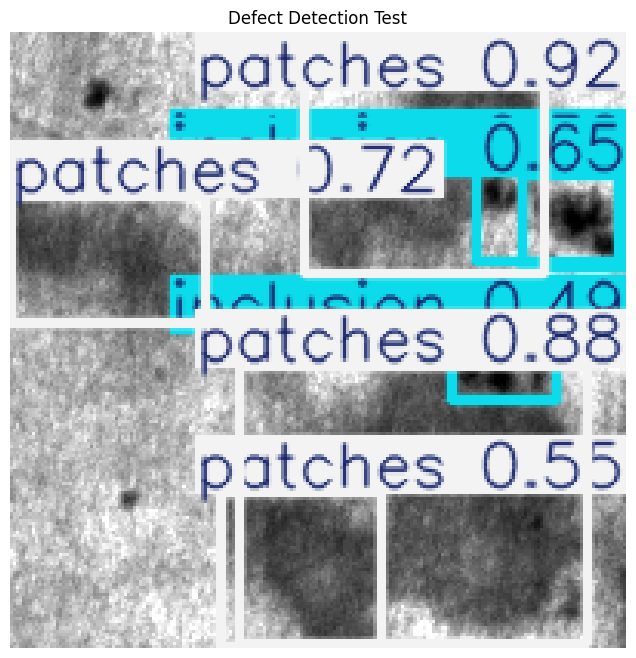

In [7]:
from ultralytics import YOLO
from IPython.display import Image, display
import cv2
import matplotlib.pyplot as plt

# Load your newly trained model
model = YOLO('/kaggle/working/best.pt')

# Pick a random image from your validation set
import glob
val_images = glob.glob('/kaggle/working/datasets/neu-det-yolo/images/val/*.jpg')
test_img = val_images[0] # You can change the index to test different images

# Run prediction
results = model.predict(test_img, conf=0.25, save=False)

# Display the image
annotated_img = results[0].plot()
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Defect Detection Test")
plt.show()

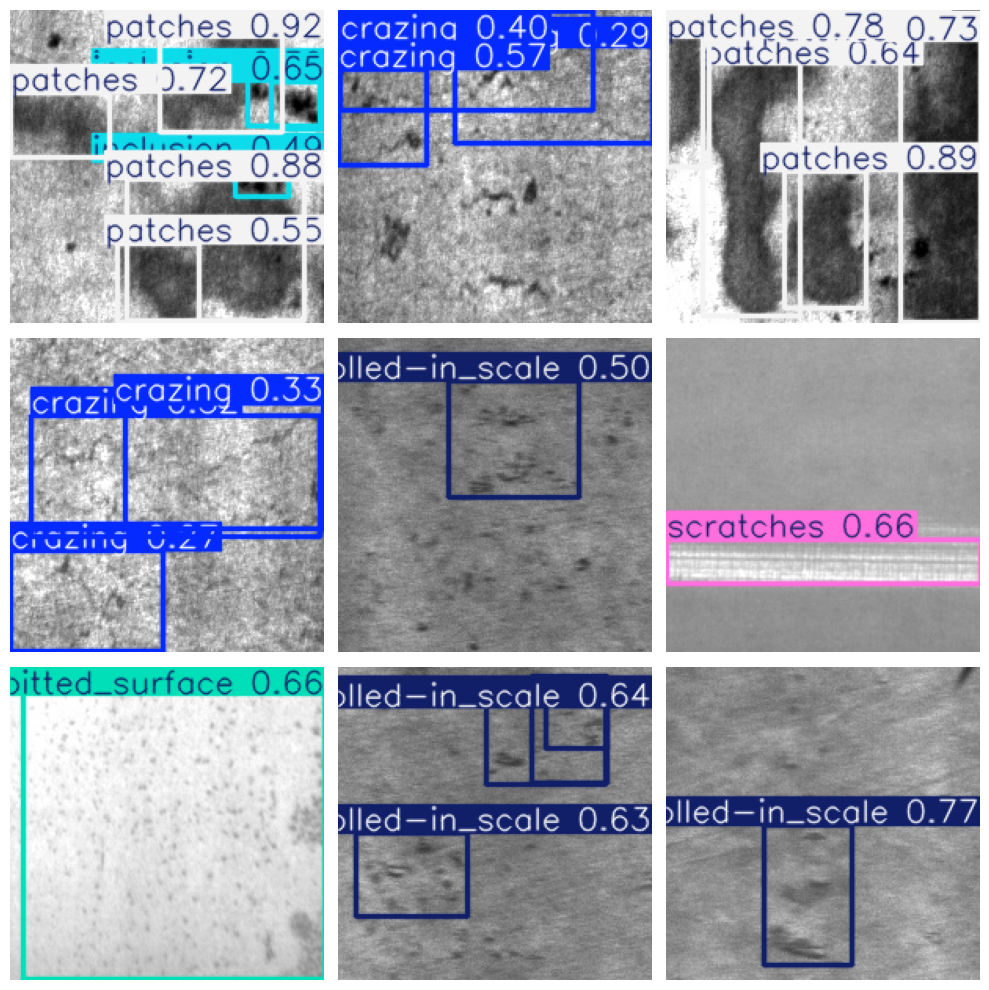

Grid image saved successfully!


In [8]:
import matplotlib.pyplot as plt
import os

# Create the results directory if it doesn't exist
os.makedirs("/kaggle/working/results", exist_ok=True)

# Pick 9 random images
test_imgs = val_images[:9]

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, img_path in zip(axes.flatten(), test_imgs):
    r = model.predict(img_path, conf=0.25, verbose=False)
    annotated = r[0].plot()
    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.tight_layout()

# Now it will save successfully
plt.savefig("/kaggle/working/results/val_predictions.png", dpi=150)
plt.show()

print("Grid image saved successfully!")

In [9]:
import shutil
import os

os.makedirs("/kaggle/working/final_output", exist_ok=True)

# 1. Copy the model
shutil.copy("/kaggle/working/best.pt", "/kaggle/working/final_output/neu_det_best.pt")

# 2. Copy training graphs (assuming YOLO saved them in the default runs folder)
# Note: Change 'neu_det_run' if you named your run differently in Cell 5
run_dir = "/kaggle/working/runs/neu_det_run" 
for file in ["results.png", "confusion_matrix.png", "confusion_matrix_normalized.png"]:
    src = os.path.join(run_dir, file)
    if os.path.exists(src):
        shutil.copy(src, f"/kaggle/working/final_output/{file}")

print("All files copied to /kaggle/working/final_output/")

All files copied to /kaggle/working/final_output/


In [10]:
from IPython.display import FileLink
FileLink('/kaggle/working/final_output/neu_det_best.pt')

/kaggle/working/final_output/neu_det_best.pt